In [7]:
import numpy as np

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
(250713,) 22050 11.37 s -1.0 0.9937439


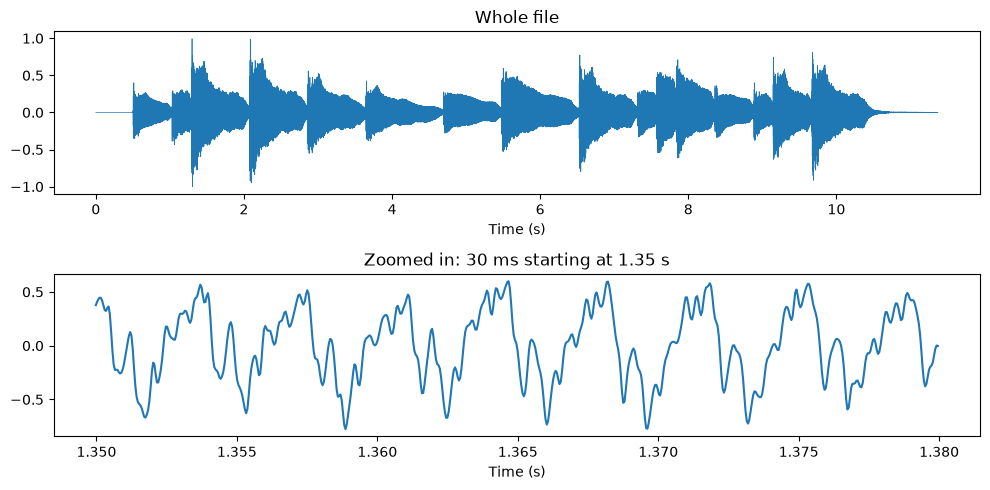

In [10]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np
from pianotrans.load import load_audio

y, sr = load_audio("../data/test/melody_000.wav")
print(y.shape, sr, f"{len(y)/sr:.2f} s", y.min(), y.max())

t = np.arange(len(y)) / sr
fig, ax = plt.subplots(2, 1, figsize=(10, 5))
ax[0].plot(t, y, lw=0.5);              ax[0].set_title("Whole file")
t_start, t_len = 1.35, 0.03          # 30 ms, just after the loud note at ~1.3 s
i0, i1 = int(t_start * sr), int((t_start + t_len) * sr)

ax[1].plot(t[i0:i1], y[i0:i1])
ax[1].set_title(f"Zoomed in: {t_len*1000:.0f} ms starting at {t_start} s")
for a in ax: a.set_xlabel("Time (s)")
plt.tight_layout()
fig.savefig("../figures/waveform_melody_000.png", dpi=150, bbox_inches="tight")

In [11]:
import pretty_midi
pm = pretty_midi.PrettyMIDI("../data/test/melody_000.mid")
for n in pm.instruments[0].notes:
    if n.start <= 1.35 < n.end:
        print(n.pitch, pretty_midi.note_number_to_name(n.pitch),
              f"{pretty_midi.note_number_to_hz(n.pitch):.1f} Hz")

61 C#4 277.2 Hz
